## Import

In [1]:
import json, os, time, pickle, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             log_loss, average_precision_score, mean_squared_error, mean_absolute_error, r2_score)
warnings.filterwarnings("ignore")
torch.set_num_threads(1)

import matplotlib.pyplot as plt

## Setup

In [2]:
SEED = 42
SET = "+ Teenhome + 5 Teenhome pairs"     # best NAM variant in V5_1
np.random.seed(SEED); torch.manual_seed(SEED)
os.makedirs("weights_V7_0", exist_ok=True); os.makedirs("media", exist_ok=True)

In [3]:
df = pd.read_csv("marketing_campaign.csv", sep="\t")
df = df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
ref_date = df["Dt_Customer"].max()
df["Customer_Tenure_Days"] = (ref_date - df["Dt_Customer"]).dt.days
df["Age"] = 2014 - df["Year_Birth"]
df = df[~df["Year_Birth"].isin([1893, 1899, 1900])].copy()
df = df[df["Income"] != 666666].copy()  # drop $666,666 income outlier (same treatment as Year_Birth sentinels)
df["Marital_Status"] = df["Marital_Status"].replace({"Absurd": "Single", "YOLO": "Single", "Alone": "Single"})
df = df.dropna(subset=["Income"]).copy()  # 2213 rows (target must not be imputed)
print("cleaned:", df.shape, "| Income max:", f"{df['Income'].max():,.0f}", "| median:", f"{df['Income'].median():,.0f}")
REG_FEATURES = ["NumCatalogPurchases","MntMeatProducts","MntWines","NumWebVisitsMonth","MntSweetProducts",
    "MntFruits","NumWebPurchases","MntGoldProds","NumStorePurchases","MntFishProducts","Kidhome","Age","NumDealsPurchases"]
X_full = df[REG_FEATURES].values; y_raw = df["Income"].values.astype(float)
print(f"features: {len(REG_FEATURES)} dims (all numeric)")

cleaned: (2212, 28) | Income max: 162,397 | median: 51,371
features: 13 dims (all numeric)


In [4]:
# Feature interaction hand-off (Feature Interaction section of regression.ipynb):
# Teenhome interacts with most spend features but is not in the 13-feature model set.
EXTRA = ["Teenhome"]
COLS_ALL = REG_FEATURES + EXTRA
X_all = df[COLS_ALL].values.astype(float)

def top_pairs(csv_path, cols, k, must_include=None, exclude=None):
    """Top-k significant (q < 0.05) pairs by effect size where both features are in `cols`."""
    t = pd.read_csv(csv_path)
    t = t[(t.q < 0.05) & t.A.isin(cols) & t.B.isin(cols)]
    if must_include is not None:
        t = t[t.A.eq(must_include) | t.B.eq(must_include)]
    if exclude is not None:
        t = t[~(t.A.eq(exclude) | t.B.eq(exclude))]
    t = t.sort_values("effect", ascending=False)
    return list(zip(t.A.head(k), t.B.head(k)))

PAIRS_13 = top_pairs("results/interaction_reg.csv", REG_FEATURES, 4)
PAIRS_T = top_pairs("results/interaction_reg.csv", COLS_ALL, 5, must_include="Teenhome")
print("pairs (13 features):", PAIRS_13); print("pairs (with Teenhome):", PAIRS_T)
SETS = {
    "13 features":                    dict(cols=REG_FEATURES, pairs=[]),
    "+ Teenhome (14)":                dict(cols=COLS_ALL, pairs=[]),
    "13 features + 4 pair nets":      dict(cols=REG_FEATURES, pairs=PAIRS_13),
    "+ Teenhome + 5 Teenhome pairs":  dict(cols=COLS_ALL, pairs=PAIRS_T),
}

def prep_split(tr_idx, te_idx, set_name):
    cols = SETS[set_name]["cols"]
    ci = [COLS_ALL.index(c) for c in cols]
    sc = StandardScaler().fit(X_all[tr_idx][:, ci])
    return sc.transform(X_all[tr_idx][:, ci]), sc.transform(X_all[te_idx][:, ci]), y_raw[tr_idx], y_raw[te_idx]

idx_all = np.arange(len(y_raw))
tr_idx, te_idx = train_test_split(idx_all, test_size=0.20, random_state=SEED)
for s_ in SETS:
    a_, b_, _, _ = prep_split(tr_idx, te_idx, s_)
    print(f"{s_:32s} train {a_.shape} test {b_.shape}")

pairs (13 features): [('MntGoldProds', 'NumWebPurchases'), ('MntFruits', 'NumDealsPurchases'), ('MntFishProducts', 'NumWebPurchases'), ('NumWebPurchases', 'NumCatalogPurchases')]
pairs (with Teenhome): [('Teenhome', 'NumCatalogPurchases'), ('Teenhome', 'NumWebVisitsMonth'), ('Teenhome', 'MntWines'), ('Teenhome', 'MntMeatProducts'), ('Teenhome', 'NumStorePurchases')]
13 features                      train (1769, 13) test (443, 13)
+ Teenhome (14)                  train (1769, 14) test (443, 14)
13 features + 4 pair nets        train (1769, 13) test (443, 13)
+ Teenhome + 5 Teenhome pairs    train (1769, 14) test (443, 14)


## Model

In [5]:
EPOCHS_MAX, BATCH, LR, WD = 100, 64, 1e-3, 1e-4     # same optimiser settings as V2_0
device = torch.device("cpu")

def run_epochs(model, X, y, loss_fn, epochs, seed, on_epoch=None):
    """Adam + cosine (T_max = 100), mini-batch 64. on_epoch(epoch, model) is called after every epoch."""
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=LR, betas=(0.9, 0.999), eps=1e-8, weight_decay=WD)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS_MAX)
    Xt = torch.from_numpy(np.asarray(X, dtype=np.float32)); yt = torch.from_numpy(np.asarray(y, dtype=np.float32)).view(-1, 1)
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(Xt), generator=g)
        for i in range(0, len(perm), BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad(); loss_fn(model(Xt[idx]), yt[idx]).backward(); opt.step()
        sch.step()
        if on_epoch is not None:
            on_epoch(ep, model)
    return model

def smooth(a, w=5):
    return np.convolve(np.pad(a, (w // 2, w // 2), mode="edge"), np.ones(w) / w, mode="valid")

def n_params(m):
    return int(sum(p.numel() for p in m.parameters()))

In [6]:
class SubNet(nn.Module):
    """Linear(n_in -> hid) - ReLU - Linear(hid -> 1). n_in = 1 for a feature, 2 for a feature pair."""
    def __init__(self, n_in=1, hid=64):
        super().__init__()
        self.fc1 = nn.Linear(n_in, hid); self.fc2 = nn.Linear(hid, 1); self.relu = nn.ReLU()
        nn.init.kaiming_normal_(self.fc1.weight, nonlinearity="relu"); nn.init.zeros_(self.fc1.bias)
        nn.init.kaiming_normal_(self.fc2.weight, nonlinearity="relu"); nn.init.zeros_(self.fc2.bias)
    def forward(self, x): return self.fc2(self.relu(self.fc1(x)))

class NAM(nn.Module):
    """Sum of per-feature subnets (+ optional 2D subnets for chosen feature pairs, i.e. NA2M) + bias."""
    def __init__(self, n_feat, pair_idx=(), hid=64):
        super().__init__()
        self.pair_idx = [tuple(p) for p in pair_idx]
        self.subs = nn.ModuleList([SubNet(1, hid) for _ in range(n_feat)])
        self.pairs = nn.ModuleList([SubNet(2, hid) for _ in self.pair_idx])
        self.b0 = nn.Parameter(torch.zeros(1))
    def forward(self, x):
        out = sum(sub(x[:, j:j + 1]) for j, sub in enumerate(self.subs)) + self.b0
        for (i, j), net in zip(self.pair_idx, self.pairs):
            out = out + net(x[:, [i, j]])
        return out

DELTA = 0.5
def make_model(v, seed, n_feat=None):
    torch.manual_seed(seed)
    cols, pairs = SETS[v]["cols"], SETS[v]["pairs"]
    idx = [(cols.index(a), cols.index(b)) for a, b in pairs]
    return NAM(n_feat=len(cols), pair_idx=idx).to(device)

In [7]:
INNER_K = 3
def to_z(y_raw_, scaler): return scaler.transform(np.log1p(y_raw_).reshape(-1, 1)).ravel()
def to_dollar(z, scaler): return np.expm1(np.clip(scaler.inverse_transform(np.asarray(z).reshape(-1, 1)).ravel(), 0.0, 15.0))   # clip keeps a bad early epoch finite

def predict_dollar(model, X, scaler):
    model.eval()
    with torch.no_grad():
        return to_dollar(model(torch.from_numpy(np.asarray(X, dtype=np.float32))).numpy().ravel(), scaler)

def fit_eval(variant, Xa, ya, Xb, yb, seed):
    """Epoch count comes from an inner K-fold on (Xa, ya) only; (Xb, yb) is scored once."""
    loss_fn = nn.HuberLoss(delta=DELTA)
    curves = []
    for k, (a, b) in enumerate(KFold(INNER_K, shuffle=True, random_state=seed).split(Xa)):
        sc = StandardScaler().fit(np.log1p(ya[a]).reshape(-1, 1))
        rm = []
        run_epochs(make_model(variant, seed + k), Xa[a], to_z(ya[a], sc), loss_fn, EPOCHS_MAX, seed + k,
                   on_epoch=lambda ep, m, b=b, sc=sc: rm.append(float(np.sqrt(mean_squared_error(ya[b], predict_dollar(m, Xa[b], sc))))))
        curves.append(rm)
    E = int(np.argmin(smooth(np.mean(curves, axis=0)))) + 1   # epoch chosen on inner validation only
    sc = StandardScaler().fit(np.log1p(ya).reshape(-1, 1))
    model = run_epochs(make_model(variant, seed + 99), Xa, to_z(ya, sc), loss_fn, E, seed + 99)
    pred = predict_dollar(model, Xb, sc)
    mse = mean_squared_error(yb, pred)
    row = {"r2": r2_score(yb, pred), "rmse": float(np.sqrt(mse)), "mae": mean_absolute_error(yb, pred), "mse": mse,
           "epochs": E, "n_params": n_params(model)}
    return row, pred

## Training

In [8]:
# same 80/20 split as every earlier version; epoch count from the inner 3-fold of the training rows only
Xa, Xb, ya, yb = prep_split(tr_idx, te_idx, SET)
row, pred = fit_eval(SET, Xa, ya, Xb, yb, SEED)
E = int(row["epochs"])
sc_y = StandardScaler().fit(np.log1p(ya).reshape(-1, 1))
model = run_epochs(make_model(SET, SEED + 99), Xa, to_z(ya, sc_y), nn.HuberLoss(delta=DELTA), E, SEED + 99).eval()
assert np.allclose(predict_dollar(model, Xb, sc_y), pred), "re-trained model differs from the evaluated one"
print(f"NAM {SET}: test R2 {row['r2']:.4f} | RMSE {row['rmse']:,.0f} | MAE {row['mae']:,.0f} | epochs {E}")

NAM + Teenhome + 5 Teenhome pairs: test R2 0.7638 | RMSE 10,592 | MAE 6,394 | epochs 95


## Evaluation

In [9]:
# Exact decomposition: prediction (log-income, z units) = b0 + sum_j f_j(x_j) + sum_pairs g_ij(x_i, x_j)
cols = SETS[SET]["cols"]; pairs = SETS[SET]["pairs"]
sx = StandardScaler().fit(X_all[tr_idx][:, [COLS_ALL.index(c) for c in cols]])
MU, SIG = float(sc_y.mean_[0]), float(sc_y.scale_[0])
def to_z_col(c, raw): j = cols.index(c); return (np.asarray(raw, dtype=float) - sx.mean_[j]) / sx.scale_[j]
def f_main(c, raw):
    with torch.no_grad():
        return model.subs[cols.index(c)](torch.tensor(to_z_col(c, raw), dtype=torch.float32).view(-1, 1)).numpy().ravel()
def g_pair(k, ta, tb):
    a_, b_ = pairs[k]
    z = np.column_stack([to_z_col(a_, ta), to_z_col(b_, tb)]).astype(np.float32)
    with torch.no_grad():
        return model.pairs[k](torch.from_numpy(z)).numpy().ravel()
raw_tr = pd.DataFrame(X_all[tr_idx][:, [COLS_ALL.index(c) for c in cols]], columns=cols)
raw_te = pd.DataFrame(X_all[te_idx][:, [COLS_ALL.index(c) for c in cols]], columns=cols)
with torch.no_grad():
    full = model(torch.from_numpy(Xb.astype(np.float32))).numpy().ravel()
b0 = float(model.b0)
check = b0 + sum(f_main(c, raw_te[c]) for c in cols) + sum(g_pair(k, raw_te[a], raw_te[b]) for k, (a, b) in enumerate(pairs))
print(f"max |sum of parts - model output| = {np.abs(check - full).max():.2e}  (the explanation is the model itself)")
assert np.abs(check - full).max() < 1e-4

# Purify each Teenhome pair (Lengerich et al. 2020): move its average over the other feature into the main effects,
# so a pair subnet only holds what the two features do TOGETHER and the main-effect curves are not cancelled by it.
T_VALS = np.array([0.0, 1.0, 2.0]); P_T = np.array([(raw_tr["Teenhome"] == t).mean() for t in T_VALS])
def pair_terms(k, df):
    """per row: pure pair part, Teenhome part, other-feature part (all centred later)"""
    a_, b_ = pairs[k]; other = b_ if a_ == "Teenhome" else a_
    def g_of(t, x):
        return g_pair(k, t, x) if a_ == "Teenhome" else g_pair(k, x, t)
    m_T = np.array([g_of(np.full(len(raw_tr), t), raw_tr[other]).mean() for t in T_VALS])          # E_x g(t, x)
    m_x = sum(p * g_of(np.full(len(df), t), df[other]) for p, t in zip(P_T, T_VALS))                  # E_t g(t, x)
    grand = float(P_T @ m_T)
    g = g_of(df["Teenhome"].values, df[other].values)
    mT_row = m_T[np.searchsorted(T_VALS, df["Teenhome"].values)]
    return g - mT_row - m_x + grand, mT_row, m_x, other, grand
def decompose(df):
    main = {c: f_main(c, df[c]) for c in cols}; pure = {}; const = b0
    for k, (a_, b_) in enumerate(pairs):
        gp, mT, mx, other, grand = pair_terms(k, df)
        main["Teenhome"] = main["Teenhome"] + mT; main[other] = main[other] + mx
        pure[f"Teenhome x {other}"] = gp; const -= grand
    return main, pure, const
m_tr, p_tr, c_tr = decompose(raw_tr)
centre = {c: v.mean() for c, v in {**m_tr, **p_tr}.items()}
bias = c_tr + sum(centre.values())
m_te, p_te, _ = decompose(raw_te)
recon = bias + sum(m_te[c] - centre[c] for c in m_te) + sum(p_te[c] - centre[c] for c in p_te)
assert np.abs(recon - full).max() < 1e-4, "purified parts must still add up to the model output"
imp = pd.Series({c: float((v - centre[c]).std() * SIG) for c, v in {**m_tr, **p_tr}.items()}).sort_values(ascending=False)
print("spread of each part on log-income after purification (std over training rows):"); print(imp.round(4).to_string())
json.dump({"test_metrics": {k: float(v) for k, v in row.items()}, "importance": imp.round(5).to_dict(), "pairs": pairs},
          open("weights_V7_0/regression_pytorch_nam_explain.json", "w"), indent=2)
torch.save(model.state_dict(), "weights_V7_0/regression_nam_best.pt")

max |sum of parts - model output| = 4.77e-07  (the explanation is the model itself)
spread of each part on log-income after purification (std over training rows):
MntWines                          0.2384
NumWebVisitsMonth                 0.1370
Teenhome                          0.1159
MntMeatProducts                   0.1156
NumDealsPurchases                 0.1107
Kidhome                           0.0796
NumWebPurchases                   0.0397
NumCatalogPurchases               0.0343
Teenhome x NumCatalogPurchases    0.0277
MntSweetProducts                  0.0237
Teenhome x MntWines               0.0235
Teenhome x MntMeatProducts        0.0210
Teenhome x NumWebVisitsMonth      0.0181
NumStorePurchases                 0.0148
MntFruits                         0.0148
MntFishProducts                   0.0116
MntGoldProds                      0.0099
Teenhome x NumStorePurchases      0.0083
Age                               0.0081


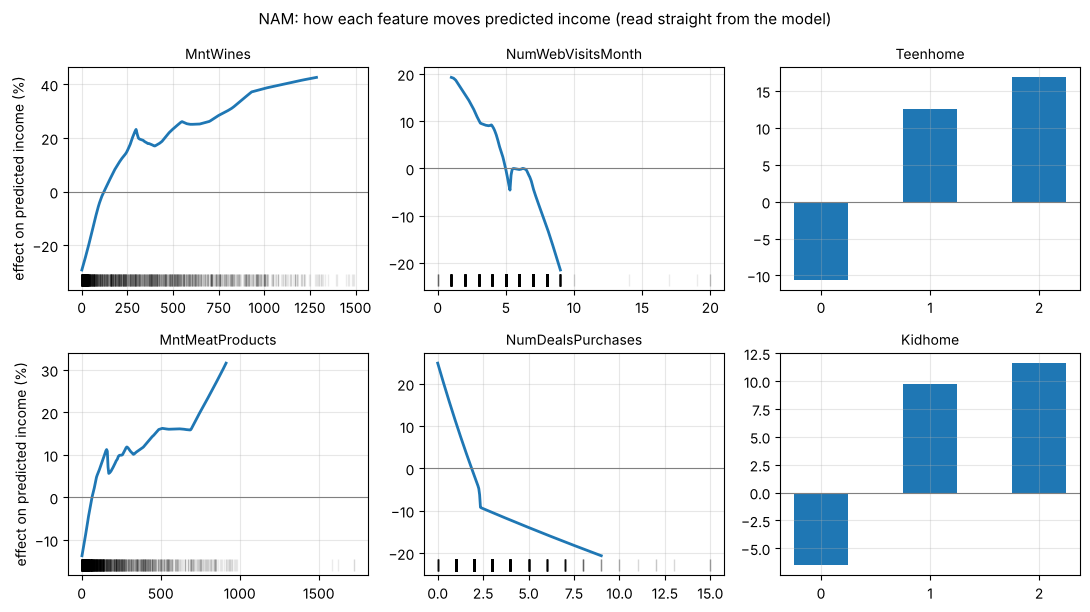

In [10]:
# Figure 1: the 6 largest single-feature parts (pair averages folded in), as % change in predicted income
pct = lambda v: 100 * (np.exp(SIG * v) - 1)
top = [c for c in imp.index if " x " not in c][:6]
fig, axes = plt.subplots(2, 3, figsize=(11, 6.2))
for ax, c in zip(axes.ravel(), top):
    raw = raw_tr[c].values
    if raw_tr[c].nunique() <= 3:                 # 0 / 1 / 2 counts: show as bars
        grid = np.sort(raw_tr[c].unique())
    else:
        grid = np.linspace(np.percentile(raw, 1), np.percentile(raw, 99), 200)
    df = pd.DataFrame({cc: np.full(len(grid), raw_tr[cc].median()) for cc in cols}); df[c] = grid
    if raw_tr[c].nunique() <= 3 and c != "Teenhome":
        ax.bar(grid, pct(f_main(c, grid) - centre[c]), width=0.5); ax.set_xticks(grid)
    elif c != "Teenhome":
        val = f_main(c, grid) + sum(sum(p * (g_pair(k, np.full(len(grid), t), grid) if pairs[k][0] == "Teenhome" else g_pair(k, grid, np.full(len(grid), t)))
                                         for p, t in zip(P_T, T_VALS)) for k in range(len(pairs)) if c in pairs[k])
        ax.plot(grid, pct(val - centre[c]), lw=2)
        ax.plot(raw, np.full_like(raw, ax.get_ylim()[0]), "|", color="k", alpha=0.08, ms=8)
    elif c == "Teenhome":
        val = f_main(c, grid) + sum(np.array([g_pair(k, np.full(len(raw_tr), t), raw_tr[pairs[k][1]]).mean() for t in T_VALS]) for k in range(len(pairs)))
        ax.bar(grid, pct(val - centre[c]), width=0.5); ax.set_xticks(T_VALS)
    ax.axhline(0, color="grey", lw=0.8); ax.set_title(c, fontsize=10); ax.grid(alpha=0.3)
axes[0, 0].set_ylabel("effect on predicted income (%)"); axes[1, 0].set_ylabel("effect on predicted income (%)")
fig.suptitle("NAM: how each feature moves predicted income (read straight from the model)", fontsize=11)
fig.tight_layout(); fig.savefig("media/nam_shapes_reg_V7_0.png", dpi=160); plt.show()

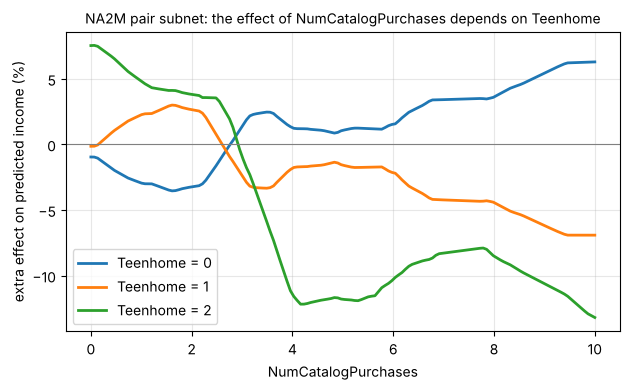

In [11]:
# Figure 2: the strongest purified Teenhome pair, one line per Teenhome value
pname = [c for c in imp.index if " x " in c][0]; other = pname.split(" x ")[1]
k = [i for i, p in enumerate(pairs) if other in p][0]
raw = raw_tr[other].values
grid = np.linspace(np.percentile(raw, 1), np.percentile(raw, 99), 150)
df = pd.DataFrame({cc: np.full(len(grid), raw_tr[cc].median()) for cc in cols}); df[other] = grid
fig, ax = plt.subplots(figsize=(6.4, 4))
for t in T_VALS:
    df["Teenhome"] = t
    gp = pair_terms(k, df)[0]
    ax.plot(grid, pct(gp - centre[pname]), lw=2, label=f"Teenhome = {int(t)}")
ax.axhline(0, color="grey", lw=0.8); ax.grid(alpha=0.3); ax.legend()
ax.set_xlabel(other); ax.set_ylabel("extra effect on predicted income (%)")
ax.set_title(f"NA2M pair subnet: the effect of {other} depends on Teenhome", fontsize=10)
fig.tight_layout(); fig.savefig("media/nam_pair_reg_V7_0.png", dpi=160); plt.show()

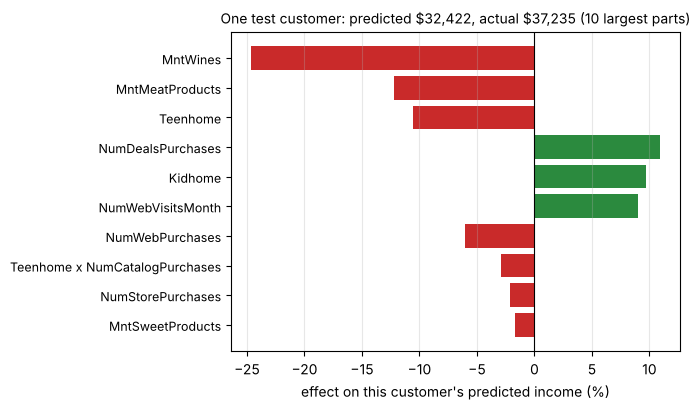

In [12]:
# Figure 3: one typical test customer, every part of the prediction (exact: the parts add up to the model output)
r = int(np.argsort(np.abs(pred - yb))[len(yb) // 2])        # median absolute error
parts_r = pd.Series({c: float(v[r] - centre[c]) for c, v in {**m_te, **p_te}.items()})
logp = MU + SIG * (bias + parts_r.sum())
assert abs(np.expm1(np.clip(logp, 0, 15)) - pred[r]) < 1.0
top_r = parts_r.reindex(parts_r.abs().sort_values(ascending=False).index)[:10]
fig, ax = plt.subplots(figsize=(7, 4.2))
v = pct(top_r.values)
ax.barh(range(len(v))[::-1], v, color=["#2b8a3e" if x > 0 else "#c92a2a" for x in v])
ax.set_yticks(range(len(v))[::-1]); ax.set_yticklabels(top_r.index, fontsize=9); ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("effect on this customer's predicted income (%)")
ax.set_title(f"One test customer: predicted \\${pred[r]:,.0f}, actual \\${yb[r]:,.0f} (10 largest parts)", fontsize=10)
ax.grid(axis="x", alpha=0.3); fig.tight_layout(); fig.savefig("media/nam_customer_reg_V7_0.png", dpi=160); plt.show()